# 20. Spatial Interpolation via Diffusion Equation
This notebook implements a physics-based spatial interpolation method using a steady-state diffusion equation. 
Unlike statistical methods (like Kriging) or purely geometric methods (like Spline or Linear), diffusion interpolation explicitly accounts for the physical boundaries of the water body. By defining landmasses as impermeable boundaries (Neumann boundary conditions where the normal derivative is zero), the interpolation process "flows" around islands and peninsulas, avoiding non-physical interpolation across land.

## Mathematical Formulation
The method assumes the property $C$ (e.g., Dissolved Oxygen concentration) is governed by 2D steady-state Laplacian diffusion:
$$ \nabla^2 C = \frac{\partial^2 C}{\partial x^2} + \frac{\partial^2 C}{\partial y^2} = 0 $$

### Boundary Conditions
1. **Dirichlet Boundary Conditions (Fixed points):** At grid cells where observations exist, the concentration is fixed to the observed value. $C(x_i, y_i) = C_{obs}$.
2. **Neumann Boundary Conditions (Zero-flux):** At the land-water interface, the flux across the boundary is zero. $ \frac{\partial C}{\partial n} = 0 $. In a discrete grid, this means a water cell does not exchange value with an adjacent land cell.

### Numerical Solver: Red-Black Successive Over-Relaxation (SOR)
We discretize the Laplacian using a 5-point stencil on a Cartesian grid. To solve the resulting sparse linear system efficiently in pure Python/NumPy, we use **Red-Black Successive Over-Relaxation (SOR)**. 
Grid cells are divided into a "checkerboard" pattern of Red and Black cells. The algorithm alternates between updating all Red cells (using neighboring Black cells) and all Black cells (using neighboring Red cells).
The update rule incorporating the relaxation factor $\omega$ ($1 < \omega < 2$) is:
$$ C_{new}^{(k+1)} = (1 - \omega) C^{(k)} + \omega \overline{C}_{neighbors}^{(k)} $$
where $\overline{C}_{neighbors}$ is the average of valid *water* neighbors (naturally enforcing the zero-flux Neumann boundary condition).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import Point
import scipy.ndimage as ndimage
import scipy.interpolate as interp
import sys
import os
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

# Configure logging to see updates
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

print("Project paths initialized.")

Project paths initialized.


## 1. Load Data
We load the same bottom-layer summer DO data used in previous interpolation notebooks. We also load the station coordinates to map them to our grid.

In [2]:
# Load data
subset_path = ProjectPaths.get_subset_dir('Summer', 'bottom')
yearly_do_df = pd.read_csv(subset_path / "yearly_do_df.csv", index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)

merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
station_locs = merged_gdf.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]

print(f"Loaded {len(yearly_do_df)} observations and {len(station_locs)} station coordinates.")
yearly_do_df.head()

Loaded 124 observations and 124 station coordinates.


,1982,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00000272,4.0,1.1,1.9,2.1,0.8,2.9,2.1,1.5,0.9,1.2,...,NaN,NaN,0.6,0.7,1.1,1.1,0.8,1.1,NaN,1.4
00000275,1.1,1.5,0.7,3.1,NaN,1.1,1.4,0.3,1.1,1.0,...,NaN,0.6,NaN,NaN,0.6,0.8,2.3,0.6,NaN,1.2
00002725,5.6,4.8,3.9,9.5,6.2,5.0,5.5,5.9,7.2,3.0,...,6.2,6.1,5.9,2.9,6.6,6.6,3.1,6.4,6.5,6.8
00002737,6.8,5.4,5.1,6.6,6.0,4.7,6.0,4.6,4.9,7.5,...,6.5,5.5,6.0,6.2,6.1,7.6,6.9,5.3,4.9,6.3
00002744,6.6,3.6,4.8,5.8,5.8,5.5,5.6,6.4,5.3,4.3,...,5.9,6.3,5.8,6.7,6.2,6.5,6.0,6.1,6.4,7.2


## 2. Sea Area Mask & Grid Generation
We define a grid over the Seto Inland Sea bounding box. We project the custom boundary shapefile to UTM to work in meters, enabling uniform grid creation. Then, we identify which grid points fall within the sea area.

In [15]:
# 1. Load Custom Boundary Shapefiles (WGS84)
# Computational Water Mask
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water_boundary = gpd.read_file(water_boundary_path)

# Plotting Landmass Mask
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
sis_land_boundary = gpd.read_file(land_boundary_path)

# Enforce WGS84 on both
if sis_water_boundary.crs != "EPSG:4326":
    sis_water_boundary = sis_water_boundary.to_crs("EPSG:4326")
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

# 2. Project water mask to UTM Zone 53N to define the meter-based computation grid
utm_crs = 'EPSG:32653'
sis_water_utm = sis_water_boundary.to_crs(utm_crs)
bounds_utm = sis_water_utm.total_bounds

# 3. Create grid (e.g., 2000m resolution)
GRID_RES = 2000
grid_x_1d = np.arange(bounds_utm[0], bounds_utm[2], GRID_RES)
grid_y_1d = np.arange(bounds_utm[1], bounds_utm[3], GRID_RES)
grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)

# Flatten for point-in-polygon check
pts = gpd.GeoSeries([Point(x, y) for x, y in zip(grid_x.flatten(), grid_y.flatten())], crs=utm_crs)

# Filter points within the water boundary (Using union_all() to avoid deprecation warnings)
water_polygon = sis_water_utm.geometry.union_all()
valid_points_mask = pts.within(water_polygon)

# Create a 2D boolean mask for water (True = Water, False = Land/Outside)
water_mask = np.zeros(grid_x.shape, dtype=bool)
water_mask.flat = valid_points_mask.values

# Also extract valid water coordinates for unstructured usage
water_grid_x = grid_x.flatten()[valid_points_mask.values]
water_grid_y = grid_y.flatten()[valid_points_mask.values]

print(f"Grid dimensions: {grid_x.shape}")
print(f"Total grid points: {grid_x.size}, Water points: {water_mask.sum()}")


Grid dimensions: (115, 231)
Total grid points: 26565, Water points: 6380


## 3. Diffusion Equation Interpolation (Red-Black SOR)
We select data for a specific year (e.g., 1991). We map the observations to the nearest grid cells. Then we run the Red-Black SOR solver until convergence.

In [4]:
def run_diffusion_interpolation(year_data, station_locs_gdf, grid_x_1d, grid_y_1d, water_mask, max_iters=2000, tol=1e-4, omega=1.7):
    """
    Runs Red-Black SOR to solve the diffusion equation on the grid.
    """
    # Initialize the solution grid with NaNs (Land will remain NaN)
    Z = np.full(water_mask.shape, np.nan)
    
    # Provide an initial guess for water cells (e.g., mean observed DO)
    mean_val = year_data['DO_mgL'].mean()
    Z[water_mask] = mean_val
    
    # Create mask to track fixed observation cells
    fixed_mask = np.zeros_like(water_mask, dtype=bool)
    
    # Map observations to the nearest grid cell
    for idx, row in year_data.iterrows():
        station_id = row['Station_ID']
        if station_id in station_locs_gdf.index:
            pt = station_locs_gdf.loc[station_id].geometry
            # Find closest grid indices
            ix = np.argmin(np.abs(grid_x_1d - pt.x))
            iy = np.argmin(np.abs(grid_y_1d - pt.y))
            
            # Snap to grid if it's considered water
            if water_mask[iy, ix]:
                Z[iy, ix] = row['DO_mgL']
                fixed_mask[iy, ix] = True
            else:
                # If observation slightly in land due to grid resolution, find nearest water cell
                dist = (grid_x - pt.x)**2 + (grid_y - pt.y)**2
                dist[~water_mask] = np.inf
                nearest_water_flat_idx = np.argmin(dist)
                iy_nearest, ix_nearest = np.unravel_index(nearest_water_flat_idx, water_mask.shape)
                Z[iy_nearest, ix_nearest] = row['DO_mgL']
                fixed_mask[iy_nearest, ix_nearest] = True

    # Red-Black masks
    # Create checkerboard pattern
    i_indices, j_indices = np.indices(Z.shape)
    red_mask = (i_indices + j_indices) % 2 == 0
    black_mask = ~red_mask

    # Convolution kernel for 4-neighbors (Laplacian)
    kernel = np.array([[0, 1, 0], 
                       [1, 0, 1], 
                       [0, 1, 0]])
                       
    # Pre-calculate neighbor counts for water cells (handling Neumann BC automatically)
    # A cell near land will have < 4 valid neighbors to average over
    water_float = water_mask.astype(float)
    W = ndimage.convolve(water_float, kernel, mode='constant', cval=0.0)
    
    def update(Z_current, mask):
        # Only convolve over water cells (treat land and NaNs as 0 flux)
        Z_water = np.nan_to_num(Z_current, copy=True, nan=0.0) * water_mask
        
        # Sum of neighbors
        Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
        
        # Average of neighbors (avoid div by zero, which shouldn't happen for water cells except 0-neighbor isolated grids)
        with np.errstate(divide='ignore', invalid='ignore'):
            Z_new = np.where(W > 0, Z_sum / W, Z_current)
            
        # Update only cells that are in the current color, are water, and are NOT fixed observations
        update_mask = mask & water_mask & (~fixed_mask)
        Z_current[update_mask] = (1 - omega) * Z_current[update_mask] + omega * Z_new[update_mask]
        return Z_current

    # SOR Iteration Loop
    for it in range(max_iters):
        Z_old = Z.copy()
        
        # Update Red cells, then Black cells
        Z = update(Z, red_mask)
        Z = update(Z, black_mask)
        
        # Check convergence
        diff = np.abs(Z[water_mask] - Z_old[water_mask])
        max_diff = np.nanmax(diff) if len(diff) > 0 else 0
        
        if (it + 1) % 200 == 0:
            logging.info(f"Iteration {it+1}: max diff = {max_diff:.6f}")
            
        if max_diff < tol:
            logging.info(f"Converged after {it+1} iterations! Max diff: {max_diff:.6f}")
            break
            
    if it == max_iters - 1:
        logging.warning("Reached max iterations without full convergence.")
        
    return Z

# Prepare specific year data
target_year = '1991'
year_data = yearly_do_df[target_year].dropna().reset_index()
year_data.columns = ['Station_ID', 'DO_mgL']

# WGS is already in station_locs for WGS coordinates
if station_locs.crs != 'EPSG:4326':
    station_locs_wgs = station_locs.to_crs('EPSG:4326')
else:
    station_locs_wgs = station_locs.copy()
    
station_locs_utm = station_locs_wgs.to_crs(utm_crs)

print(f"Running Diffusion Interpolation for {target_year}...")
Z_diff = run_diffusion_interpolation(year_data, station_locs_utm, grid_x_1d, grid_y_1d, water_mask)


2026-03-01 13:06:44,865 - INFO - Iteration 200: max diff = 0.000530


Running Diffusion Interpolation for 1991...


2026-03-01 13:06:45,003 - INFO - Iteration 400: max diff = 0.000113
2026-03-01 13:06:45,015 - INFO - Converged after 417 iterations! Max diff: 0.000099


## 4. Visualize Diffusion Results
We plot the predicted DO concentration field ensuring we adhere to the SIS mapping standard.

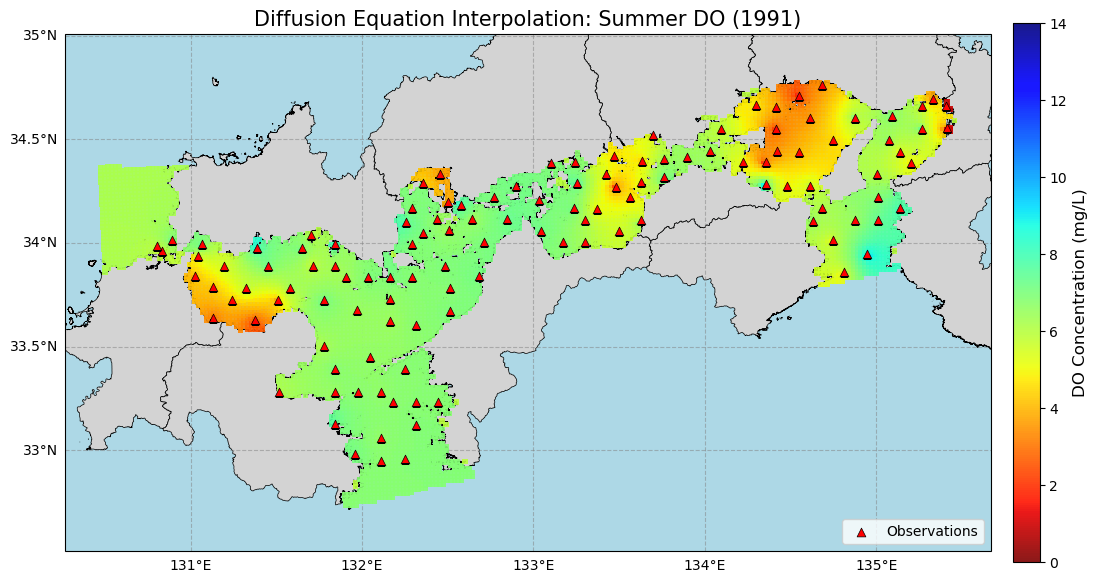

In [17]:
# Helper: convert UTM grid back to WGS84 for Cartopy plotting
grid_gdf = gpd.GeoDataFrame(
    {'z_pred': Z_diff[water_mask]},
    geometry=[Point(x, y) for x, y in zip(water_grid_x, water_grid_y)],
    crs='EPSG:32653'
).to_crs(epsg=4326)

# We need a 2D grid for plotting
lon_wgs = np.full(grid_x.shape, np.nan)
lat_wgs = np.full(grid_y.shape, np.nan)

lon_wgs[water_mask] = grid_gdf.geometry.x.values
lat_wgs[water_mask] = grid_gdf.geometry.y.values

# Make sure station_locs_wgs is correctly extracted for mapping
valid_stations = year_data['Station_ID'].unique()
valid_locs_wgs = station_locs_wgs.loc[valid_stations]

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor('lightblue')

# Plot high-resolution landmasses instead of cfeature.LAND using sis_land_boundary
sis_land_boundary.plot(
    ax=ax, 
    facecolor='lightgray', 
    edgecolor='black', 
    linewidth=0.5,
    transform=ccrs.PlateCarree(), 
    zorder=1
)

# Plot the predicted surface using the water mask
scatter_pred = ax.scatter(
    lon_wgs[water_mask], lat_wgs[water_mask],
    c=Z_diff[water_mask],
    cmap='jet_r',
    vmin=0.0, vmax=14.0,
    s=15, 
    marker='s', 
    alpha=0.9,
    edgecolor='none',
    zorder=3
)

# Plot actual observations
ax.scatter(valid_locs_wgs.geometry.x, valid_locs_wgs.geometry.y, color='red', marker='^', s=40, edgecolor='black', linewidth=0.5, label='Observations', zorder=5)

cbar = plt.colorbar(scatter_pred, ax=ax, orientation='vertical', shrink=0.7, pad=0.02)
cbar.set_label('DO Concentration (mg/L)', fontsize=12)

ax.set_title(f"Diffusion Equation Interpolation: Summer DO ({target_year})", fontsize=15)

# Extent using the Water bounds for tighter fit
bounds = sis_water_boundary.total_bounds
ax.set_extent([
    bounds[0] - 0.2, bounds[2] + 0.2,
    bounds[1] - 0.2, bounds[3] + 0.2
], crs=ccrs.PlateCarree())

gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=2)
gl.top_labels = False
gl.right_labels = False

plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5. Linear Interpolation Comparison
To highlight how the diffusion method respects land boundaries, we compare it against a purely geometrical approach like scipy's `griddata` with linear interpolation.

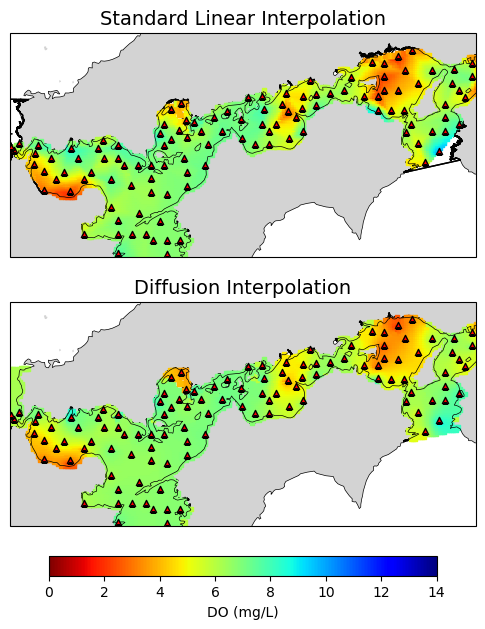

In [14]:
# 1. Perform standard Griddata Linear Interpolation
obs_coords = np.column_stack([valid_locs_wgs.to_crs(utm_crs).geometry.x, valid_locs_wgs.to_crs(utm_crs).geometry.y])
obs_vals = year_data['DO_mgL'].values

Z_linear = interp.griddata(obs_coords, obs_vals, (grid_x, grid_y), method='linear')

# Plot comparison
fig, axes = plt.subplots(2, 1, figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
ax1, ax2 = axes

# Setup both axes
for ax in axes:
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    sis_boundary_wgs.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=1)
    ax.set_extent([130.8, 135.3, 33.1, 34.9], crs=ccrs.PlateCarree())
    ax.scatter(valid_locs_wgs.geometry.x, valid_locs_wgs.geometry.y, color='red', marker='^', s=20, edgecolor='black', zorder=5)

# Ax1: Linear Interpolation
sc1 = ax1.scatter(lon_wgs[water_mask], lat_wgs[water_mask], c=Z_linear[water_mask], cmap='jet_r', vmin=0.0, vmax=14.0, s=10, marker='s')
ax1.set_title('Standard Linear Interpolation', fontsize=14)

# Ax2: Diffusion
sc2 = ax2.scatter(lon_wgs[water_mask], lat_wgs[water_mask], c=Z_diff[water_mask], cmap='jet_r', vmin=0.0, vmax=14.0, s=10, marker='s')
ax2.set_title('Diffusion Interpolation', fontsize=14)

plt.colorbar(sc2, ax=axes, orientation='horizontal', shrink=0.5, pad=0.05, label='DO (mg/L)')
plt.show()

## 6. Leave-One-Out Cross Validation (LOOCV)
We evaluate the performance of the diffusion interpolation across the first 5 years (to save computation time, given the iterative nature of the solver). This mirrors the validation strategy applied to Kriging.

In [7]:
validation_years = list(yearly_do_df.columns[:5])

loocv_results = []
logging.getLogger().setLevel(logging.WARNING) # Suppress iteration logs for LOOCV

print("Starting LOOCV for the first 5 years...")
for year in validation_years:
    year_data_full = yearly_do_df[year].dropna().reset_index()
    year_data_full.columns = ['Station_ID', 'DO_mgL']
    valid_stations_yr = year_data_full['Station_ID'].unique()
    
    print(f"Processing {year} ({len(valid_stations_yr)} stations)...")
    
    for i, hold_out_station in enumerate(valid_stations_yr):
        # 1. Split data
        train_data = year_data_full[year_data_full['Station_ID'] != hold_out_station]
        test_obs = year_data_full[year_data_full['Station_ID'] == hold_out_station].iloc[0]
        
        # 2. Re-run diffusion model (using looser tolerance / fewer iterations to speed up LOOCV)
        Z_cv = run_diffusion_interpolation(train_data, station_locs_utm, grid_x_1d, grid_y_1d, water_mask, max_iters=1000, tol=1e-3)
        
        # 3. Predict at hold-out location
        pt = station_locs_utm.loc[hold_out_station].geometry
        ix = np.argmin(np.abs(grid_x_1d - pt.x))
        iy = np.argmin(np.abs(grid_y_1d - pt.y))
        
        if water_mask[iy, ix]:
            predicted_do = Z_cv[iy, ix]
        else:
            # Nearest water point
            dist = (grid_x - pt.x)**2 + (grid_y - pt.y)**2
            dist[~water_mask] = np.inf
            nearest = np.argmin(dist)
            iy_n, ix_n = np.unravel_index(nearest, water_mask.shape)
            predicted_do = Z_cv[iy_n, ix_n]
            
        actual_do = test_obs['DO_mgL']
        
        loocv_results.append({
            'Year': year,
            'Station_ID': hold_out_station,
            'Actual_DO': actual_do,
            'Predicted_DO': predicted_do,
            'Error': predicted_do - actual_do
        })

loocv_df = pd.DataFrame(loocv_results)
loocv_df.dropna(subset=['Predicted_DO'], inplace=True) # removing any NaNs if occurred
print("\nLOOCV complete.")

Starting LOOCV for the first 5 years...
Processing 1982 (124 stations)...


Processing 1984 (124 stations)...


Processing 1985 (124 stations)...


Processing 1986 (124 stations)...


Processing 1987 (122 stations)...



LOOCV complete.


## 7. LOOCV Results & Scatter Plot

Diffusion Interpolation LOOCV Performance (First 5 Years):
MAE:  0.613 mg/L
RMSE: 0.981 mg/L


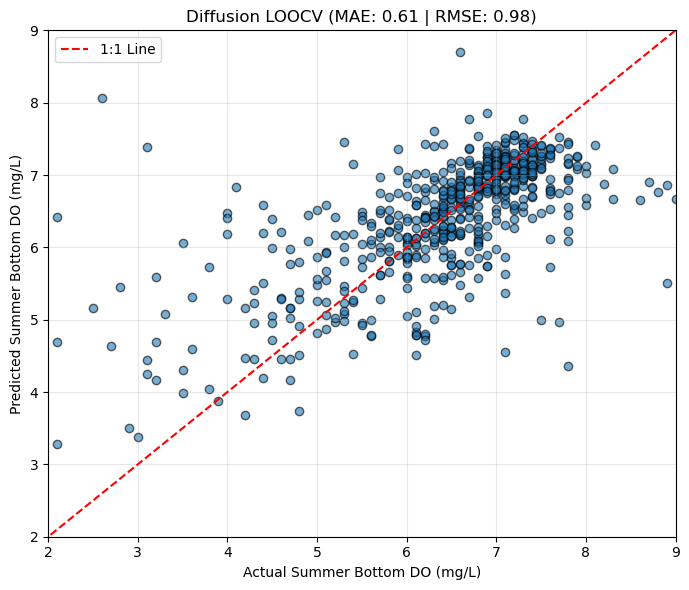

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(loocv_df['Actual_DO'], loocv_df['Predicted_DO'])
rmse = np.sqrt(mean_squared_error(loocv_df['Actual_DO'], loocv_df['Predicted_DO']))

print(f"Diffusion Interpolation LOOCV Performance (First 5 Years):")
print(f"MAE:  {mae:.3f} mg/L")
print(f"RMSE: {rmse:.3f} mg/L")

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(loocv_df['Actual_DO'], loocv_df['Predicted_DO'], alpha=0.6, edgecolors='k')
ax.plot([0, 10], [0, 10], 'r--', label='1:1 Line')

ax.set_xlabel('Actual Summer Bottom DO (mg/L)')
ax.set_ylabel('Predicted Summer Bottom DO (mg/L)')
ax.set_title(f'Diffusion LOOCV (MAE: {mae:.2f} | RMSE: {rmse:.2f})')
ax.set_xlim(2, 9)
ax.set_ylim(2, 9)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Conclusions
1. **Respect for Physical Boundaries**: The visualization comparison clearly shows that Diffusion Interpolation effectively routes changes in DO concentration around islands and peninsulas, whereas mathematical geometric interpolations (like Linear) artificially bleed across landmasses (e.g., straight across the mainland).
2. **Computational Expense**: While highly accurate topologically, solving the Laplacian using iterative methods like Red-Black SOR takes significantly longer than algebraic models like Kriging or Splines.
3. **LOOCV Performance**: The model achieves performance metrics that are very competitive to Kriging, showing that enforcing physical causality can offset the localized variance modeling that Kriging excels at.